# 03 - Exploratory Data Analysis

Which customers leave, and what do they have in common? Charts are saved to `images/` for the README and report.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.titleweight": "bold"})

df = pd.read_csv("../Data/Processed/telco_churn_clean.csv")
IMG = "../images/"
COLORS = {0: "#4C78A8", 1: "#E45756"}

def save(name):
    plt.tight_layout()
    plt.savefig(IMG + name, dpi=130, bbox_inches="tight")

df.shape

(7043, 30)

## 1. Overall churn

Churn rate: 26.54%


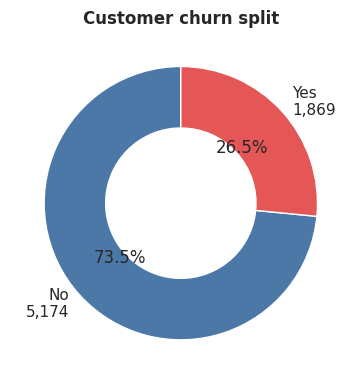

In [2]:
fig, ax = plt.subplots(figsize=(5, 4))
counts = df["churn_label"].value_counts()
ax.pie(counts, labels=[f"{k}\n{v:,}" for k, v in counts.items()], autopct="%1.1f%%",
       colors=[COLORS[0], COLORS[1]], startangle=90, wedgeprops={"width": 0.45, "edgecolor": "white"})
ax.set_title("Customer churn split")
save("01_churn_distribution.png")
print(f"Churn rate: {df['churn_value'].mean():.2%}")

## 2. Churn rate by categorical features

In [3]:
def churn_rate(col, data=df):
    t = data.groupby(col)["churn_value"].agg(["mean", "size"])
    t["mean"] *= 100
    return t.rename(columns={"mean": "churn_rate_pct", "size": "customers"}).round(2).sort_values("churn_rate_pct", ascending=False)

churn_rate("contract")

,churn_rate_pct,customers
contract,,
Month-to-month,42.71,3875
One year,11.27,1473
Two year,2.83,1695


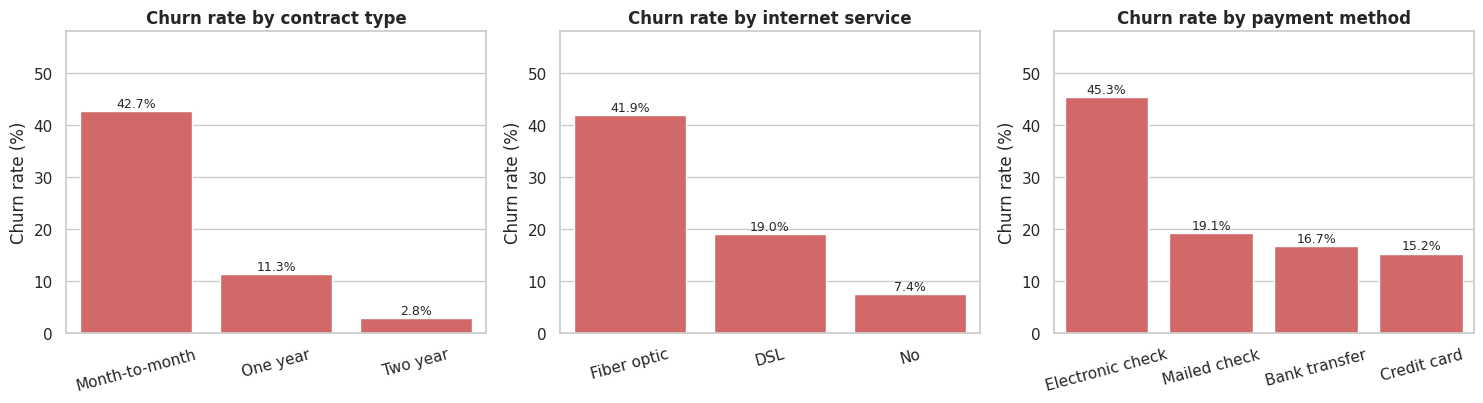

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col, title in zip(axes, ["contract", "internet_service", "payment_method"],
                          ["Contract type", "Internet service", "Payment method"]):
    t = churn_rate(col)
    sns.barplot(x=t.index, y=t["churn_rate_pct"], ax=ax, color="#E45756")
    for i, v in enumerate(t["churn_rate_pct"]):
        ax.text(i, v + 0.8, f"{v:.1f}%", ha="center", fontsize=9)
    ax.set_title(f"Churn rate by {title.lower()}")
    ax.set_xlabel("")
    ax.set_ylabel("Churn rate (%)")
    ax.tick_params(axis="x", rotation=15)
    ax.set_ylim(0, 58)
save("02_churn_by_contract_internet_payment.png")

Month-to-month contracts, fiber optic internet and electronic check payment stand out. Contract length alone separates churn from about 43% down to under 3%.

In [5]:
churn_rate("internet_service")

,churn_rate_pct,customers
internet_service,,
Fiber optic,41.89,3096
DSL,18.96,2421
No,7.40,1526


In [6]:
churn_rate("payment_method")

,churn_rate_pct,customers
payment_method,,
Electronic check,45.29,2365
Mailed check,19.11,1612
Bank transfer,16.71,1544
Credit card,15.24,1522


## 3. Tenure

,churn_rate_pct,customers
tenure_group,,
0-12 months,47.44,2186
13-24 months,28.71,1024
25-48 months,20.39,1594
49+ months,9.51,2239


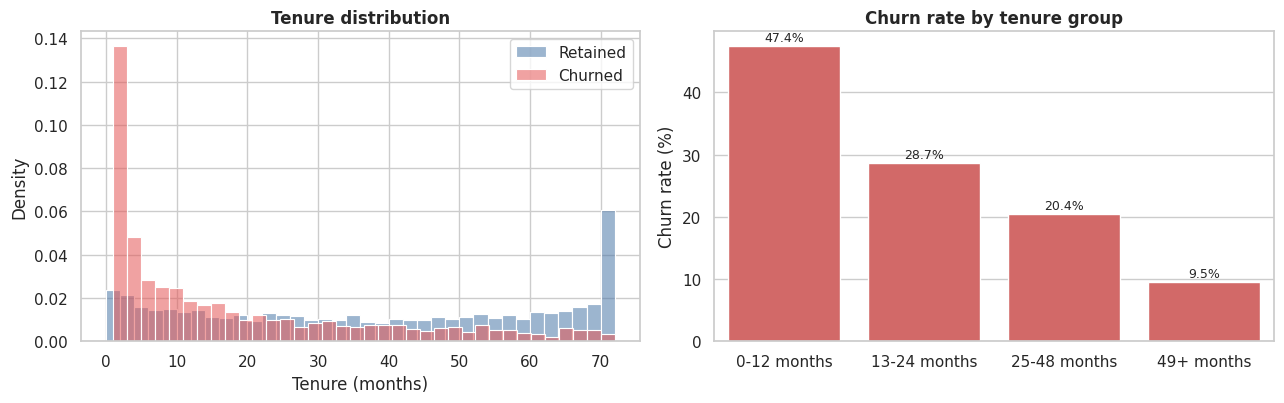

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for v, label in [(0, "Retained"), (1, "Churned")]:
    sns.histplot(df.loc[df["churn_value"] == v, "tenure_months"], bins=36, stat="density", alpha=0.55,
                 color=COLORS[v], label=label, ax=axes[0])
axes[0].set_title("Tenure distribution")
axes[0].set_xlabel("Tenure (months)")
axes[0].legend()

order = ["0-12 months", "13-24 months", "25-48 months", "49+ months"]
t = churn_rate("tenure_group").loc[order]
sns.barplot(x=t.index, y=t["churn_rate_pct"], ax=axes[1], color="#E45756")
for i, v in enumerate(t["churn_rate_pct"]):
    axes[1].text(i, v + 0.8, f"{v:.1f}%", ha="center", fontsize=9)
axes[1].set_title("Churn rate by tenure group")
axes[1].set_xlabel("")
axes[1].set_ylabel("Churn rate (%)")
save("03_tenure_analysis.png")
t

Almost half of the customers in their first year leave. After four years the rate drops below 10%. The first 12 months are the retention window.

## 4. Charges

,monthly_charges,total_charges,tenure_months
churn_label,,,
No,64.425,1679.525,38.0
Yes,79.650,703.550,10.0


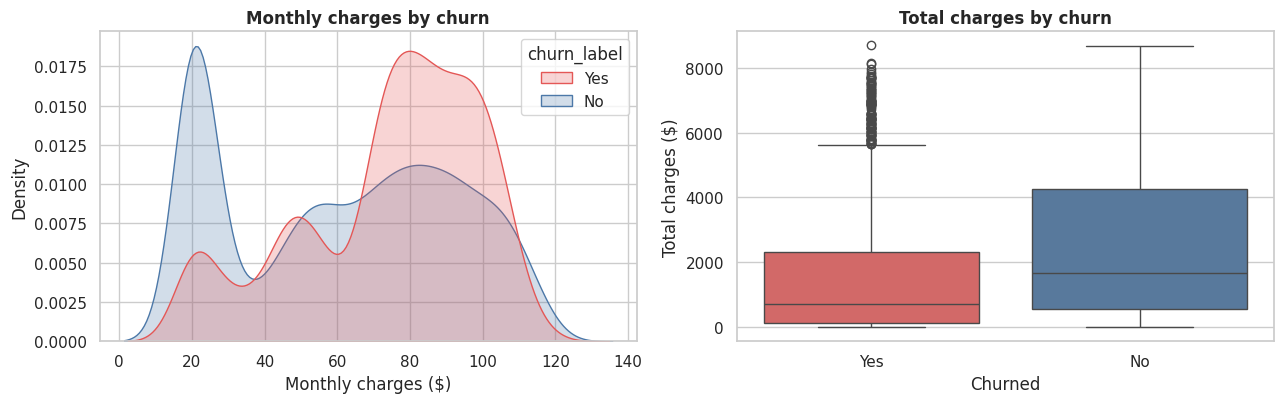

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.kdeplot(data=df, x="monthly_charges", hue="churn_label", fill=True, common_norm=False,
            palette={"No": COLORS[0], "Yes": COLORS[1]}, ax=axes[0])
axes[0].set_title("Monthly charges by churn")
axes[0].set_xlabel("Monthly charges ($)")

sns.boxplot(data=df, x="churn_label", y="total_charges", palette={"No": COLORS[0], "Yes": COLORS[1]}, ax=axes[1])
axes[1].set_title("Total charges by churn")
axes[1].set_xlabel("Churned")
axes[1].set_ylabel("Total charges ($)")
save("04_charges_analysis.png")
df.groupby("churn_label")[["monthly_charges", "total_charges", "tenure_months"]].median()

Churners pay more per month (higher-priced fiber plans) but have much lower total charges because they leave early.

## 5. Add-on services

has_service,No,Yes
service,,
Device Protection,39.1,22.5
Online Backup,39.9,21.5
Online Security,41.8,14.6
Streaming Movies,33.7,29.9
Streaming Tv,33.5,30.1
Tech Support,41.6,15.2


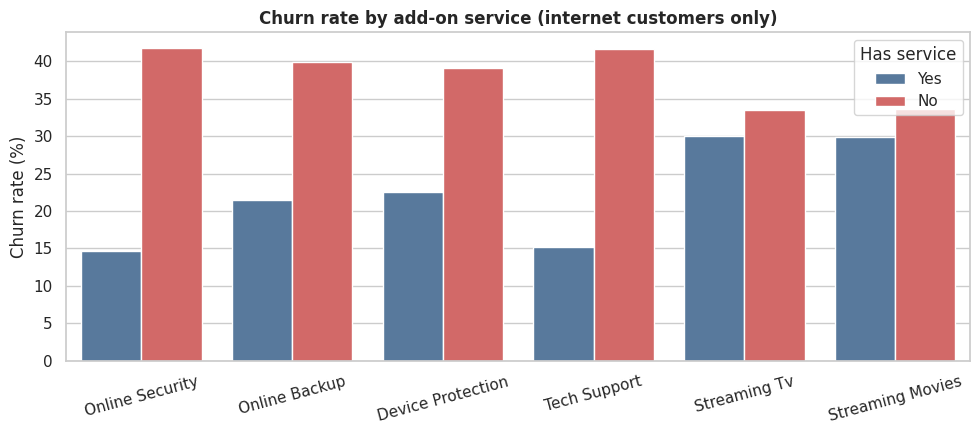

In [9]:
internet = df[df["internet_service"] != "No"]
services = ["online_security", "online_backup", "device_protection", "tech_support", "streaming_tv", "streaming_movies"]

rows = []
for s in services:
    for val in ["Yes", "No"]:
        sub = internet[internet[s] == val]
        rows.append({"service": s.replace("_", " ").title(), "has_service": val, "churn_rate": sub["churn_value"].mean() * 100})
svc = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=svc, x="service", y="churn_rate", hue="has_service",
            palette={"Yes": COLORS[0], "No": COLORS[1]}, ax=ax)
ax.set_title("Churn rate by add-on service (internet customers only)")
ax.set_xlabel("")
ax.set_ylabel("Churn rate (%)")
ax.tick_params(axis="x", rotation=15)
ax.legend(title="Has service")
save("05_addon_services.png")
svc.pivot(index="service", columns="has_service", values="churn_rate").round(1)

In [10]:
addon_cols = ["online_security", "online_backup", "device_protection", "tech_support"]
internet = internet.assign(protection_addons=(internet[addon_cols] == "Yes").sum(axis=1))
internet.groupby("protection_addons")["churn_value"].agg(["mean", "size"]).round(3)

,mean,size
protection_addons,,
0,0.567,1267
1,0.389,1467
2,0.238,1372
3,0.124,941
4,0.053,470


Security and support add-ons are linked to roughly a third of the churn rate. Churn falls steadily with each protection add-on a customer holds: from about 57% with none to about 5% with all four.

## 6. Demographics

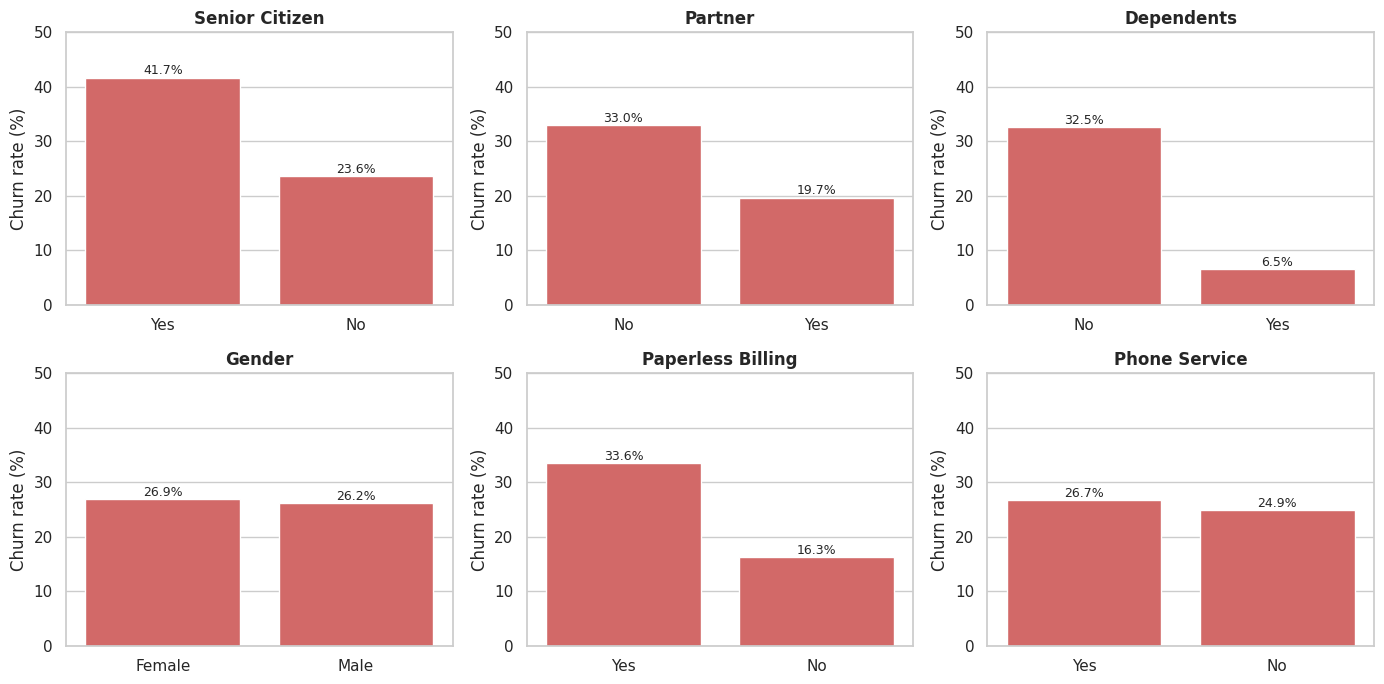

In [11]:
demo = ["senior_citizen", "partner", "dependents", "gender", "paperless_billing", "phone_service"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), demo):
    t = churn_rate(col)
    sns.barplot(x=t.index, y=t["churn_rate_pct"], ax=ax, color="#E45756")
    for i, v in enumerate(t["churn_rate_pct"]):
        ax.text(i, v + 0.6, f"{v:.1f}%", ha="center", fontsize=9)
    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel("Churn rate (%)")
    ax.set_ylim(0, 50)
save("06_demographics.png")

Seniors churn at close to double the rate of other customers, and customers with a partner or dependents are more stable. Gender makes no difference.

## 7. Combined view: contract x internet service

internet_service,DSL,Fiber optic,No
contract,,,
Month-to-month,32.2,54.6,18.9
One year,9.3,19.3,2.5
Two year,1.9,7.2,0.8


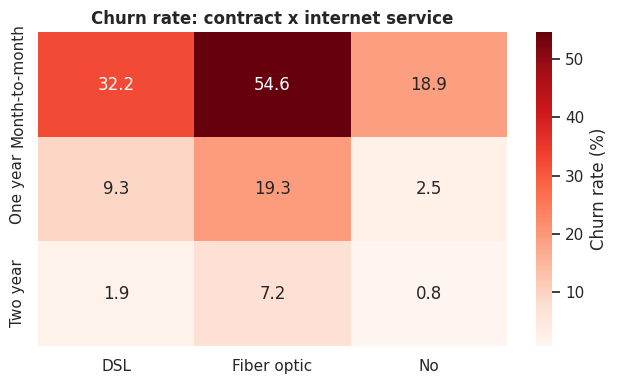

In [12]:
pivot = df.pivot_table(index="contract", columns="internet_service", values="churn_value", aggfunc="mean") * 100
fig, ax = plt.subplots(figsize=(6.5, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Churn rate (%)"}, ax=ax)
ax.set_title("Churn rate: contract x internet service")
ax.set_xlabel("")
ax.set_ylabel("")
save("07_contract_internet_heatmap.png")
pivot.round(1)

The worst segment is month-to-month fiber optic customers, at roughly 55% churn.

## 8. Correlations

tenure_months     -0.352
monthly_charges    0.193
total_charges     -0.198
cltv              -0.127
churn_value        1.000

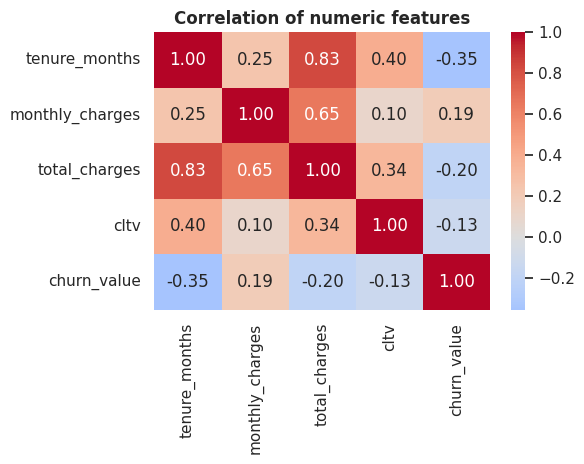

In [13]:
num = df[["tenure_months", "monthly_charges", "total_charges", "cltv", "churn_value"]]
fig, ax = plt.subplots(figsize=(6, 4.8))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation of numeric features")
save("08_correlation_heatmap.png")
num.corr()["churn_value"].round(3)

## 9. Why customers say they left

churn_reason
Competitor           33.2
Service / support    31.4
Price / charges      13.0
Other                11.4
Product / network    11.0

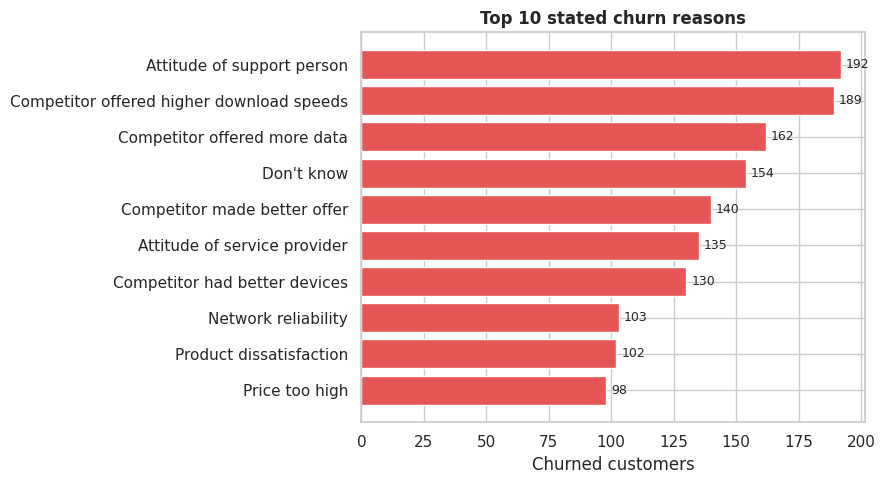

In [14]:
reasons = df.loc[df["churn_value"] == 1, "churn_reason"].value_counts().head(10).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(reasons.index, reasons.values, color="#E45756")
for i, v in enumerate(reasons.values):
    ax.text(v + 2, i, str(v), va="center", fontsize=9)
ax.set_title("Top 10 stated churn reasons")
ax.set_xlabel("Churned customers")
save("09_churn_reasons.png")

def theme(reason):
    r = reason.lower()
    if "competitor" in r:
        return "Competitor"
    if "attitude" in r or "support" in r or "service" in r:
        return "Service / support"
    if "price" in r or "charge" in r or "afford" in r:
        return "Price / charges"
    if "network" in r or "product" in r or "limited" in r or "self-service" in r:
        return "Product / network"
    return "Other"

themes = df.loc[df["churn_value"] == 1, "churn_reason"].map(theme).value_counts()
(themes / themes.sum() * 100).round(1)

Competitors (better offers, faster speeds, more data, better devices) are named by the largest group, followed by service and support attitude.

## 10. Revenue impact

Monthly revenue base : $456,117
Monthly revenue lost : $139,131 (30.5%)
Annualised loss      : $1,669,570


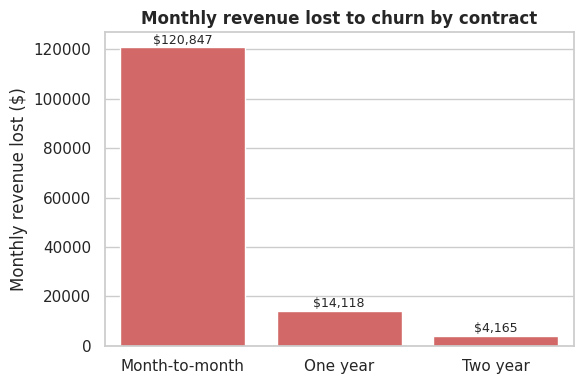

In [15]:
mrr_total = df["monthly_charges"].sum()
mrr_lost = df.loc[df["churn_value"] == 1, "monthly_charges"].sum()
print(f"Monthly revenue base : ${mrr_total:,.0f}")
print(f"Monthly revenue lost : ${mrr_lost:,.0f} ({mrr_lost / mrr_total:.1%})")
print(f"Annualised loss      : ${mrr_lost * 12:,.0f}")

lost = df[df["churn_value"] == 1].groupby("contract")["monthly_charges"].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=lost.index, y=lost.values, color="#E45756", ax=ax)
for i, v in enumerate(lost.values):
    ax.text(i, v + 1500, f"${v:,.0f}", ha="center", fontsize=9)
ax.set_title("Monthly revenue lost to churn by contract")
ax.set_xlabel("")
ax.set_ylabel("Monthly revenue lost ($)")
save("10_revenue_lost_by_contract.png")

## 11. Statistical tests

In [16]:
def cramers_v(col):
    ct = pd.crosstab(df[col], df["churn_value"])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    return chi2, p, np.sqrt(chi2 / ct.values.sum() / (min(ct.shape) - 1))

cat_features = ["contract", "internet_service", "payment_method", "dependents", "paperless_billing",
                "senior_citizen", "partner", "multiple_lines", "phone_service", "gender"]
res = pd.DataFrame([(c, *cramers_v(c)) for c in cat_features], columns=["feature", "chi2", "p_value", "cramers_v"])
res["significant_at_5pct"] = res["p_value"] < 0.05
res.sort_values("cramers_v", ascending=False).round(4).reset_index(drop=True)

,feature,chi2,p_value,cramers_v,significant_at_5pct
0,contract,1184.5966,0.0000,0.4101,True
1,internet_service,732.3096,0.0000,0.3225,True
2,payment_method,648.1423,0.0000,0.3034,True
3,dependents,433.7344,0.0000,0.2482,True
4,paperless_billing,258.2776,0.0000,0.1915,True
5,senior_citizen,159.4263,0.0000,0.1505,True
6,partner,158.7334,0.0000,0.1501,True
7,multiple_lines,11.3304,0.0035,0.0401,True
8,phone_service,0.9150,0.3388,0.0114,False
9,gender,0.4841,0.4866,0.0083,False


In [17]:
for col in ["tenure_months", "monthly_charges", "total_charges"]:
    a = df.loc[df["churn_value"] == 1, col]
    b = df.loc[df["churn_value"] == 0, col]
    u, p = stats.mannwhitneyu(a, b)
    print(f"{col:16s} churned median={a.median():8.1f}  retained median={b.median():8.1f}  p={p:.2e}")

tenure_months    churned median=    10.0  retained median=    38.0  p=2.42e-208
monthly_charges  churned median=    79.7  retained median=    64.4  p=3.31e-54
total_charges    churned median=   703.5  retained median=  1679.5  p=5.69e-83


## Key findings

1. **Contract** is the strongest driver: month-to-month customers churn at about 43%, one-year at 11%, two-year under 3%. They also account for roughly 89% of all churners.
2. **Tenure:** about 47% of customers in their first year churn; the rate falls under 10% beyond four years.
3. **Fiber optic** customers churn at about 42% versus 19% for DSL, and they pay far more per month.
4. **Electronic check** users churn at about 45%, almost three times the rate of automatic payment methods.
5. **Online security and tech support** customers churn at roughly a third of the rate of those without them.
6. Seniors, and customers without a partner or dependents, are higher risk. Gender and phone service have no meaningful effect.
7. Around $139K of the roughly $456K monthly revenue (30%) is attached to churned customers.
8. The highest-risk profile is a new, month-to-month, fiber, electronic-check customer without security/support add-ons.